In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 3 — Challenge A: multinomial logistic regression (R2)

**Scope:** P3.1, P3.2 and the Challenge A part of P3.5.

> **Team code style (delete this cell before submitting).** The team must be able to defend every line.
>
> - Prefer tools seen in class or named in the statement. If you cannot explain a line in one sentence, rewrite it.
> - Plain `for` loops and `if`s, one step per line, clear variable names. No lambdas, classes or long chains.
> - Same results, simpler code. After simplifying, restart, run all and check that the numbers did not change.
> - Interpretation goes in Markdown cells, in English. Check your notebook with `revisor_notebook.py`.
>
> **Shared names, so that the notebooks can be joined:** `dev` (development table), `X`, `y` (cyber target), `z` (storage target), `latency_ns`, `NOMINAL`, `NUMERIC`, `FEATURES`, `REFERENCE_LEVELS`, `make_preprocessor()`, `folds` (list of `(train_idx, val_idx)`), `CLASS_NAMES` (cyber).

## Setup from R1 and R4

Paste here the cells published by R1 and R4. They are **not** pasted into the final notebook.

In [2]:
# TODO: paste the data, preprocessing and folds cells
# TEMPORARY setup

# Standard library
import json
import time

# Numerical and table libraries
import numpy as np
import pandas as pd 

# Plotting library
import matplotlib.pyplot as plt

# scikit-learn tools to build the preprocessing block
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Folder where the cyber data live
DATA_DIR = "../../datos/cyber/"

# Development table: one row per network connection
dev = pd.read_csv(DATA_DIR + "cyber_development.csv")

# Read the file that maps each class code to its name
with open(DATA_DIR + "cyber_class_codes.json") as fh:
    raw_codes = json.load(fh)

# JSON keys are always text, so we convert each key to an integer
CLASS_NAMES = {}
for key in raw_codes:
    CLASS_NAMES[int(key)] = raw_codes[key]

# Categorical predictors
NOMINAL = ["proto", "service", "conn_state"]

# Numeric predictors
NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]

# All predictors together: categorical first, then numeric
FEATURES = NOMINAL + NUMERIC

# Predictor table and cyber target
X = dev[FEATURES]
y = dev["attack_code"]

# PLACEHOLDER reference levels: R1 publishes the real ones
REFERENCE_LEVELS = {"proto": "tcp", "service":"-", "conn_state": "SF"}

def make_preprocessor():
    # Numeric columns: first log1p, then standardise
    numeric_steps = Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])

    # List of the level to drop for each categorical column, in the same order as NOMINAL
    drop_list = []
    for col in NOMINAL:
        drop_list.append(REFERENCE_LEVELS[col])

    # One-hot encoding without the reference level; unseen levels become all zeros
    nominal_steps = OneHotEncoder(drop=drop_list, handle_unknown="ignore")

    # Apply each block to its columns; sparse_threshold=0 returns a normal (dense) array
    return ColumnTransformer([
        ("nominal", nominal_steps, NOMINAL),
        ("numeric", numeric_steps, NUMERIC),
    ], sparse_threshold=0)


In [3]:
# Canonical folds file
canonical = pd.read_csv(DATA_DIR + "cyber_folds.csv")

# Both files must have the same number of rows
assert len(canonical) == len(dev)
assert canonical["row_id"].is_unique

# Attach the fold of each row to the development table by row_id
aligned = dev[["row_id"]].merge(canonical, on="row_id", how="left", validate="one_to_one")

# Every development row must have received a fold
assert aligned["fold_id"].notna().all()

# Fold number of each row, as a NumPy array
fold_id = aligned["fold_id"].to_numpy()

# The file must contain exactly the five canonical folds
assert list(np.unique(fold_id)) == [0, 1, 2, 3, 4]

# Build the list of (train_idx, val_idx) pairs, one pair per fold
folds = []
for f in range(5):
    # Training rows: all rows that are NOT in fold f
    train_idx = np.where(fold_id != f)[0]
    # Validation rows: the rows that ARE in fold f
    val_idx = np.where(fold_id == f)[0]
    folds.append((train_idx, val_idx))

# Checks on each fold
y_check = y.to_numpy()
for f in range(5):
    train_idx = folds[f][0]
    val_idx = folds[f][1]
    # Every row is either in training or in validation, never in both
    assert len(train_idx) + len(val_idx) == len(dev)
    # Training must contain all ten classes, otherwise coef_ would lose rows
    assert len(np.unique(y_check[train_idx])) == len(CLASS_NAMES)
    print("fold", f, "| training rows:", len(train_idx), "| validation rows:", len(val_idx))


fold 0 | training rows: 27942 | validation rows: 6986
fold 1 | training rows: 27942 | validation rows: 6986
fold 2 | training rows: 27943 | validation rows: 6985
fold 3 | training rows: 27942 | validation rows: 6986
fold 4 | training rows: 27943 | validation rows: 6985


# P3.1 — Multinomial logistic regression

## Two different things are called `C`
The course uses $C$ for the **number of classes**. The `scikit-learn` parameter `C` means something unrelated: the **inverse regularisation strength**, where a larger value means a weaker penalty. Following the Unit 7 notebook, the library parameter is always passed from a named constant, `C_SKLEARN_UNREGULARISED`, so the two are never confused. With `C = inf` the penalty term disappears completely, which is what p3.1 asks for.

In [4]:
# TODO: imports for this part
# Multinomial logistic regression
from sklearn.linear_model import LogisticRegression

# Metrics: accuracy, F1, confusion matrix and per-class precision/recall/F1/support
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.metrics import precision_recall_fscore_support

# Fixed settings, written once here before any model is built

# scikit-learn's C is the INVERSE regularisation strength, NOT the number of classes
# Infinity means the penalty term is removed completely
C_SKLEARN_UNREGULARISED = np.inf
# Maximum number of solver iterations: only so the solver can finish, not a modelling choice
MAX_ITER = 5000
# Tolerance for the numerical checks (obtained from Unit 7 notebook)
ATOL_PRED = 1e-9

In [5]:
# TODO: model on the required route of Section 2, inside a Pipeline.
# Print the effective penalty parameters from get_params().

def make_logreg():
    # Each call returns a NEW, untrained pipeline: R1's preprocessing + logistic regression
    return Pipeline([
        # Step 1: the preprocessing block from R1
        ("prep", make_preprocessor()),
        # Step 2: C = infinity means no penalty, no class weights, enough iterations to converge
        ("logreg", LogisticRegression(
            C=C_SKLEARN_UNREGULARISED,
            solver = "lbfgs",
            class_weight=None, 
            max_iter=MAX_ITER,
        )),
    ])

# Build one pipeline only to read its parameters
logreg = make_logreg()

# get_params() returns a dictionary with every parameter of the logistic regression step
params = logreg.named_steps["logreg"].get_params()

# Print the parameters that show there is no penalty
for name in ["C", "l1_ratio", "penalty", "class_weight", "solver", "max_iter"]:
    # Some names may not exist in every scikit-learn version, so we check first
    if name in params:
        print(name, "=", params[name])

C = inf
l1_ratio = 0.0
penalty = deprecated
class_weight = None
solver = lbfgs
max_iter = 5000


In [6]:
# TODO: macro F1 for each of the five folds, its mean and spread, weighted F1 and accuracy
# Class codes in increasing order:
CLASS_CODES = sorted(CLASS_NAMES)

# Class names in the same order as CLASS_CODES
class_names = []
for code in CLASS_CODES:
    class_names.append(CLASS_NAMES[code])

# Target as a NumPy array, to index it by position
y_true = y.to_numpy()

# Out-of-fold predictions: each row will be predicted by the model that did NOT train on it
oof_pred = np.zeros(len(y_true), dtype=int)

# One dictionary of results per fold
lr_rows = []

# One dictionary per fold with the shape of coef_ and the gssapi count
lr_coef_info = []

# Loop over the five canonical folds; k is the fold number
for k in range(5):
    train_idx = folds[k][0]
    val_idx = folds[k][1]
    # New untrained pipeline for this fold
    model = make_logreg()

    # Start the clock
    t0 = time.perf_counter()
    # Train on the training rows of this fold
    model.fit(X.iloc[train_idx], y_true[train_idx])
    # Seconds spent fitting
    fit_time = time.perf_counter() - t0

    # Check that the model saw all ten classes, in the order of CLASS_CODES
    assert list(model.classes_) == CLASS_CODES

    # Predict the validation rows
    pred = model.predict(X.iloc[val_idx])
    # Save these predictions in their positions of the out-of-fold array
    oof_pred[val_idx] = pred

    # The logistic regression step, to read coef_ and n_iter_
    lr = model.named_steps["logreg"]

    # Metrics of this fold
    lr_rows.append({
        "fold": k,
        "macro_f1": f1_score(y_true[val_idx], pred, average="macro"),
        "weighted_f1": f1_score(y_true[val_idx], pred, average="weighted"),
        "accuracy": accuracy_score(y_true[val_idx], pred),
        "fit_time_s": fit_time,
        # n_iter_ is an array with one value for the multinomial model
        "iterations": lr.n_iter_[0],
    })

    # How many training rows have service = gssapi in this fold
    gssapi_count = (X.iloc[train_idx]["service"] == "gssapi").sum()

    # Store the shape of coef_ beside that count
    lr_coef_info.append({
        "fold": k,
        "coef_shape": lr.coef_.shape,
        "gssapi_rows_in_training": gssapi_count,
    })

# Turn the list of dictionaries into a table, one row per fold
lr_folds = pd.DataFrame(lr_rows).set_index("fold")
display(lr_folds.round(4))

# Macro F1 column, used several times below
lr_macro = lr_folds["macro_f1"]

# Mean of the five folds 
print("Macro F1 mean:", round(lr_macro.mean(), 4))
# Spread as range
printed = lr_macro.round(4)
print("Macro F1 spread (max - min):", round(printed.max() - printed.min(), 4))
print("Weighted F1 mean:", round(lr_folds["weighted_f1"].mean(), 4))
print("Accuracy mean:", round(lr_folds["accuracy"].mean(), 4))
# Fit time
print("Fit time mean(s):", round(lr_folds["fit_time_s"].mean(), 2),
      "| min:", round(lr_folds["fit_time_s"].min(),2),
      "| max:", round(lr_folds["fit_time_s"].max(),2))
print("All fits converged before max_iter:", (lr_folds["iterations"] < MAX_ITER).all())

C:\Users\diana\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,macro_f1,weighted_f1,accuracy,fit_time_s,iterations
fold,,,,,
0,0.8407,0.8548,0.8561,8.1020,971
1,0.8332,0.8487,0.8506,6.0580,725
2,0.8453,0.8583,0.8596,7.1048,827
3,0.8353,0.8511,0.8521,7.8539,967
4,0.8361,0.8535,0.8544,9.2107,1099


Macro F1 mean: 0.8381
Macro F1 spread (max - min): 0.0121
Weighted F1 mean: 0.8533
Accuracy mean: 0.8546
Fit time mean(s): 7.67 | min: 6.06 | max: 9.21
All fits converged before max_iter: True


**About the warning above.** `OneHotEncoder` warns *"Found unknown categories in columns [1] during transform"*. Column 1 is `service`: the development set contains a single `service = gssapi` row, and in fold 3 that row is in validation, so the encoder fitted on the training rows never saw that level. With `handle_unknown="ignore"` the row is encoded as all zeros, which means it is treated as the reference level `service = -`. This affects one validation row out of 6986 and has no visible effect on the metrics. No warning about the penalty appears: `get_params()` shows `C = inf`, and in this scikit-learn version `penalty` is reported as `deprecated`, so the penalty is switched off through `C` alone.

In [7]:
# TODO: per-class precision, recall and F1 beside their support, and the labelled confusion matrix
# Per-class metrics computed on the out-of-fold predictions (each row predicted by a model
# that did not train on it). labels=CLASS_CODES fixes the order of the classes.
# zero_division=0: if a class is never predicted, its precision is 0 instead of an error
precision, recall, f1, support = precision_recall_fscore_support(y_true, oof_pred, labels=CLASS_CODES, zero_division=0)

# One row per class, with its support beside the three metrics
per_class = pd.DataFrame({
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
}, index = class_names)

# Sort by support so the rare classes are easy to find at the bottom
per_class = per_class.sort_values("support", ascending=False)
display(per_class.round(4))

# Confusion matrix: rows = true class, columns = predicted class, same order as CLASS_CODES
cm = confusion_matrix(y_true, oof_pred, labels=CLASS_CODES)

# Labels for rows and columns, so the table can be read without remembering the codes
row_labels = []
col_labels = []
for name in class_names:
    row_labels.append("true: " + name)
    col_labels.append("pred: " + name)

cm_table = pd.DataFrame(cm, index=row_labels, columns=col_labels)
display(cm_table)

# Safety check: the matrix must count every development row exactly once
assert cm.sum() == len(y_true)

,precision,recall,f1,support
ddos,0.7880,0.9121,0.8455,4800
dos,0.8113,0.7723,0.7913,4800
xss,0.9041,0.7677,0.8303,4800
injection,0.8997,0.9138,0.9067,4800
normal,0.8017,0.8717,0.8352,4800
password,0.9622,0.9075,0.9341,4800
scanning,0.8908,0.8543,0.8722,3542
backdoor,0.8080,0.9924,0.8907,1573
mitm,0.6508,0.4584,0.5379,805
ransomware,0.9333,0.9423,0.9378,208


,pred: backdoor,pred: ddos,pred: dos,pred: injection,pred: mitm,pred: normal,pred: password,pred: ransomware,pred: scanning,pred: xss
true: backdoor,1561,0,0,0,6,2,0,0,1,3
true: ddos,2,4378,14,103,11,42,70,1,19,160
true: dos,17,26,3707,11,77,661,3,0,290,8
true: injection,5,233,34,4386,7,26,26,1,4,78
true: mitm,0,72,71,13,369,206,16,0,35,23
true: normal,0,37,289,96,41,4184,47,5,15,86
true: password,343,10,12,3,15,36,4356,0,1,24
true: ransomware,1,0,1,0,1,3,1,196,0,5
true: scanning,0,21,420,2,31,37,0,1,3026,4
true: xss,3,779,21,261,9,22,8,6,6,3685


**Interpretation.** 

Across the five canonical folds the unpenalised multinomial logistic regression reaches a mean macro F1 of **0.8381** (fold values from 0.8332 to 0.8453, range 0.0121), so the result is stable across folds. Weighted F1 (0.8533) and accuracy (0.8546) are only about 0.015 higher. Six of the ten classes have exactly 4800 rows, so the class sizes are not very unequal and the averages stay close; most of the gap comes from a single class.

That class is `mitm`: F1 0.538, recall 0.458. 206 of its rows are predicted as `normal`, and 72 and 71 as `ddos` and `dos`. Without `mitm`, the macro F1 of the other nine classes would be about 0.87. The rarest class, `ransomware` (208 rows), is in fact the best one (F1 0.938), so rarity alone does not explain the errors: what matters is how much a class overlaps with the others in the predictor space.

The largest confusions are between classes with similar traffic: `xss` predicted as `ddos` (779 rows) and as `injection` (261), `dos` predicted as `normal`(661) and as `scanning` (290), `scanning` predicted as `dos` (420), and `password` predicted as `backdoor` (343). This last confusion explains why `backdoor` has recall 0.992 but precision only 0.808. All five fits converged before `max_iter`.

In [8]:
# TODO: print the shape of coef_
# Shape of coef_ in each fold, beside how many training rows had service = gssapi
lr_coef_table = pd.DataFrame(lr_coef_info).set_index("fold")
display(lr_coef_table)

# Final model: the same pipeline fitted once on ALL development rows
# It is only used to read and interpret the coefficients in P3.2
final_model = make_logreg()
final_model.fit(X, y_true)

# The logistic regression step of the final model
final_lr = final_model.named_steps["logreg"]

# Check the class order, as in every fold
assert list(final_lr.classes_) == CLASS_CODES

print("coef_ shape of the final model:", final_lr.coef_.shape)
print("intercept_ shape of the final model:", final_lr.intercept_.shape)
print("number of transformed predictors:", len(final_model.named_steps["prep"].get_feature_names_out()))


,coef_shape,gssapi_rows_in_training
fold,,
0,"(10, 30)",1
1,"(10, 30)",1
2,"(10, 30)",1
3,"(10, 29)",0
4,"(10, 30)",1


coef_ shape of the final model: (10, 30)
intercept_ shape of the final model: (10,)
number of transformed predictors: 30


**What the shape of `coef_` implies.** 

`coef_` has shape **(10, 30)**: one row per class and one column per transformed predictor. The 30 columns are 22 dummy columns plus the 8 standardised numeric columns; `intercept_` has the shape (10,). There are $C = 10$ rows, not the $C - 1 = 9$ of the reference-class form, so a single row cannot be read on its own: adding the same vector to every row gives exactly the same probabilities.

The shape is not the same in every fold. The development set has a single `service = gssapi` row. In fold 3 that row is in validation, so the training rows contain no `gssapi`, the encoder creates one column fewer and `coef_` has shape **(10, 29)**, against (10, 30) in the other four folds. The coefficients of fold 3 therefore cannot be compared column by column with those of the other folds.

# P3.2 — The parameterisation bridge

**Reference class and why.** 

We use `normal` as the reference class. Every differenced coefficient then reads as "this attack versus normal traffic", which is the question that matters for detecting attacks. The choice does not change the model: subtracting the same row from every class leaves all probabilities identical, so it only changes how the coefficients are written down.

In [9]:
# TODO: construct w_c and b_c (Section 3)
# Look up the codes of "normal" and "ransomware" by their names
REFERENCE_CLASS = None
RANSOMWARE = None
for code in CLASS_NAMES:
    if CLASS_NAMES[code] == "normal":
        REFERENCE_CLASS = code
    if CLASS_NAMES[code] == "ransomware":
        RANSOMWARE = code

# Name of the reference class, to use in titles and sentences
REFERENCE_NAME = CLASS_NAMES[REFERENCE_CLASS]

# Number of ransomware rows
RANSOMWARE_SUPPORT = (y_true == RANSOMWARE).sum()
print("reference class:", REFERENCE_NAME, "| ransomware support:", RANSOMWARE_SUPPORT)

# Stored parameterisation: one row of coefficients per class
beta = final_lr.coef_
# Stored intercepts: one per class
alpha = final_lr.intercept_

# Position of the reference class inside the rows of coef_
r_pos = list(final_lr.classes_).index(REFERENCE_CLASS)

# Reference-class parameterisation: subtract the reference row from every row
w = beta - beta[r_pos]
# Same for the intercepts
b = alpha - alpha[r_pos]

# Stop the notebook if the reference row is not all zeros
assert np.all(w[r_pos] == 0)
# Stop the notebook if the reference intercept is not zero
assert b[r_pos] == 0
print("reference row of w and reference intercept b_r are exactly zero")

# Column names produced by the preprocessor
long_names = final_model.named_steps["prep"].get_feature_names_out()

# Keep only the part after "__"
names = []
for name in long_names:
    names.append(name.split("__")[-1])

# Table of differenced coefficients: rows = predictors, columns = classes
coef_diff = pd.DataFrame(w.T, index = names, columns = class_names)
display(coef_diff.round(3))

reference class: normal | ransomware support: 208
reference row of w and reference intercept b_r are exactly zero


,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
proto_icmp,-36.352,-38.911,-27.804,-42.523,24.097,0.0,-28.051,-38.204,-27.746,-47.206
proto_udp,-11.910,-22.259,0.796,-20.761,-2.751,0.0,-7.384,-18.123,-9.561,-31.963
service_dce_rpc,12.723,-3.159,-0.757,-4.045,0.033,0.0,-0.543,2.514,0.218,-3.921
service_dns,-10.213,8.705,0.775,1.027,-2.002,0.0,18.668,11.121,9.824,17.138
service_ftp,-2.692,-7.035,-7.759,-1.839,-6.319,0.0,53.447,1.253,-2.851,-12.063
service_gssapi,0.473,0.434,-1.162,0.459,0.163,0.0,0.248,3.315,0.451,0.486
service_http,-28.760,-11.572,-2.333,-12.389,-11.808,0.0,34.328,-9.286,-8.038,-14.302
service_smb,18.435,-0.854,-1.254,-0.407,-0.400,0.0,-0.823,0.001,-0.111,-13.765
service_smb;gssapi,14.046,-0.469,-0.128,-0.230,-0.469,0.0,-1.879,0.022,-0.008,-10.590
service_ssl,-31.845,-19.441,3.040,-27.357,-8.528,0.0,40.562,-9.518,0.587,-41.523


In [10]:
# TODO: verify the Topic 7 probabilities against predict_proba for at least one observation
# Transform all rows with the fitted preprocessor
X_trans = final_model.named_steps["prep"].transform(X)

# One observation step by step: the first ransomware row

# Position of the first row whose true class is ransomware
row = np.where(y_true == RANSOMWARE)[0][0]

# The transformed predictors of that row
x_row = X_trans[row]

# Topic 7 score of each class: b_c + w_c · x (the @ sign is the dot product)
scores = b + w @ x_row

# Subtract the largest score: probabilities do not change, and np.exp cannot overflow
scores = scores - scores.max()

# Softmax: exponentiate each score and divide by their sum
proba_topic7 = np.exp(scores) / np.exp(scores).sum()

# Probabilities given by scikit-learn for the same row
proba_sklearn = final_model.predict_proba(X.iloc[[row]])[0]

# Show both columns side by side
check = pd.DataFrame(
    {"topic 7 (w, b)": proba_topic7, "predict_proba": proba_sklearn},
    index=class_names)
print("row_id:", dev["row_id"].iloc[row], "| true class:", CLASS_NAMES[y_true[row]])
display(check.round(6))

# Largest absolute difference between the two routes
max_diff = np.abs(proba_topic7 - proba_sklearn).max()
# Stop the notebook if they disagree more than the tolerance
assert max_diff <= ATOL_PRED

# The same check for one row of every class
for code in CLASS_CODES:
    # First row of this class
    row = np.where(y_true == code)[0][0]
    # Topic 7 probabilities, exactly as above
    scores = b + w @ X_trans[row]
    scores = scores - scores.max()
    proba_topic7 = np.exp(scores) / np.exp(scores).sum()
    # scikit-learn probabilities
    proba_sklearn = final_model.predict_proba(X.iloc[[row]])[0]
    # Largest absolute difference between the two
    max_diff = np.abs(proba_topic7 - proba_sklearn).max()
    print(CLASS_NAMES[code], "| max difference:", max_diff)
    # Stop the notebook if the two probabilities disagree for this class
    assert max_diff <= ATOL_PRED

print("topic 7 probabilities match predict_proba for one row of every class")

row_id: C00277 | true class: ransomware


,"topic 7 (w, b)",predict_proba
backdoor,0.000000,0.000000
ddos,0.000000,0.000000
dos,0.000000,0.000000
injection,0.000027,0.000027
mitm,0.000000,0.000000
normal,0.000000,0.000000
password,0.000000,0.000000
ransomware,0.973866,0.973866
scanning,0.000000,0.000000
xss,0.026107,0.026107


backdoor | max difference: 4.718447854656915e-16
ddos | max difference: 7.771561172376096e-16
dos | max difference: 6.938893903907228e-16
injection | max difference: 6.661338147750939e-16
mitm | max difference: 6.661338147750939e-16
normal | max difference: 1.6653345369377348e-15
password | max difference: 2.0261570199409107e-15
ransomware | max difference: 5.551115123125783e-16
scanning | max difference: 5.273559366969494e-16
xss | max difference: 8.673617379884035e-17
topic 7 probabilities match predict_proba for one row of every class


**The three parameterisations.**

1. The model's probabilities: For each connection $x$ the model gives $P(Y=c \mid x) = \exp(\alpha_c + \beta_c^\top x) \,/\, \sum_k \exp(\alpha_k + \beta_k^\top x)$. These are what `predict_proba` returns, and they are the only part fixed by the data: every valid way of writing the coefficients leads to the same probabilities.

2. scikit-learn's stored parameterisation: `coef_` stores one row $\beta_c$ per class (shape 10 × 30) and `intercept_` one $\alpha_c$ per class. This form is not identifiable: adding the same vector to every $\beta_c$, and the same number to every $\alpha_c$, leaves all probabilities unchanged. With no penalty, nothing picks one of these equivalent solutions, so a single stored row has no meaning on its own.

3. The reference-class parameterisation: Subtracting the `normal` row gives $w_c = \beta_c - \beta_{\text{normal}}$ and $b_c = \alpha_c - \alpha_{\text{normal}}$, so $w_{\text{normal}} = 0$ and $b_{\text{normal}} = 0$ exactly (checked with `assert`). Only $C - 1 = 9$ rows are free, and they are identifiable: each $w_c$ is the change in log-odds of class $c$ versus `normal`. For the first ransomware row (`row_id` C00277) the softmax of $b + w\,x$ gives $P(\text{ransomware}) = 0.973866$, the same value as `predict_proba`. Over one row of every class, the largest difference between the two routes is $2.0 \times 10^{-15}$, far below the tolerance $10^{-9}$.

In [11]:
# StandardScaler fitted inside the final model 
scaler = final_model.named_steps["prep"].named_transformers_["numeric"].named_steps["scale"]

# Standard deviation of log1p(x) for each numeric column, in the order of NUMERIC
LOG1P_SD = {}
for i in range(len(NUMERIC)):
    LOG1P_SD[NUMERIC[i]] = scaler.scale_[i]

# ------- Numeric predictor
class_name = "ddos"
col = "src_bytes"
# Odds ratio: exp of the differenced coefficient 
ratio = np.exp(coef_diff.loc[col, class_name])
# One standard deviation of log1p(x) mean multiplying (1 + x) by this factor
factor = np.exp(LOG1P_SD[col])
print("Holding the other predictors fixed, one standard deviation more in log1p(" + col + ")",
      "(multiplying 1 +", col, "by", round(factor, 2), ")",
      "multiplies the odds of", class_name, "versus", REFERENCE_NAME, "by", ratio)

# -------- Categorical predictor
class_name = "scanning"
col = "conn_state"
level = "REJ"
# The dummy column for this level is called "conn_state_REJ"
ratio = np.exp(coef_diff.loc[col + "_" + level, class_name])
print("Holding the other predictors fixed, a connection with", col, "=", level,
      "instead of the reference level", col, "=", REFERENCE_LEVELS[col],
      "has its odds of", class_name, "versus", REFERENCE_NAME,
      "multiplied by", ratio)

# --------- Rare class, beside its support
class_name = "ransomware"
col = "dst_bytes"
ratio = np.exp(coef_diff.loc[col, class_name])
print("Holding the other predictors fixed, one standard deviation more in log1p(" + col + ")",
      "multiplies the odds of ransomware (support:", RANSOMWARE_SUPPORT, ")",
      "versus", REFERENCE_NAME, "by", ratio)

print()
print("These are associations in the fitted model, not causal effects.")

Holding the other predictors fixed, one standard deviation more in log1p(src_bytes) (multiplying 1 + src_bytes by 18.58 ) multiplies the odds of ddos versus normal by 1.707025563392716
Holding the other predictors fixed, a connection with conn_state = REJ instead of the reference level conn_state = SF has its odds of scanning versus normal multiplied by 426523355.2071786
Holding the other predictors fixed, one standard deviation more in log1p(dst_bytes) multiplies the odds of ransomware (support: 208 ) versus normal by 0.00040243028711903233

These are associations in the fitted model, not causal effects.


**Odds ratios (Section 3 rule).**

- Numeric predictor: holding the other predictors fixed, one standard deviation more in `log1p(src_bytes)` (that is, multiplying $1 + \text{src\_bytes}$ by 18.58) multiplies the odds of `ddos` versus `normal` by **1.71** (coefficient 0.535), about 71 % higher odds. "Holding the other predictors fixed" is a strong condition here, because `src_bytes` moves together with `src_ip_bytes`.
- Categorical predictor: holding the other predictors fixed, a connection with `conn_state = REJ` instead of the reference level `conn_state = SF` has its odds of `scanning` versus `normal` multiplied by about **4.3 × 10⁸** (coefficient 19.87). The direction is plausible, because rejected connection attempts are typical of scanning, but the size is not credible as a number: it is what an unpenalised model produces when a level almost separates two classes.
- Rare class, beside its support: `ransomware` has only **208** rows. Holding the other predictors fixed, one standard deviation more in `log1p(dst_bytes)` multiplies its odds versus `normal` by about **0.0004** (coefficient −7.82), that is, it divides them by about 2,500. With so few rows and no penalty, this value is very unstable and should not be over-read.

These are associations in the fitted model, not causal effects. The model has no penalty, so very large or very small odds ratios (especially for rare classes) can appear simply because nothing limits the size of the coefficients. They do not by themselves prove perfect separation.

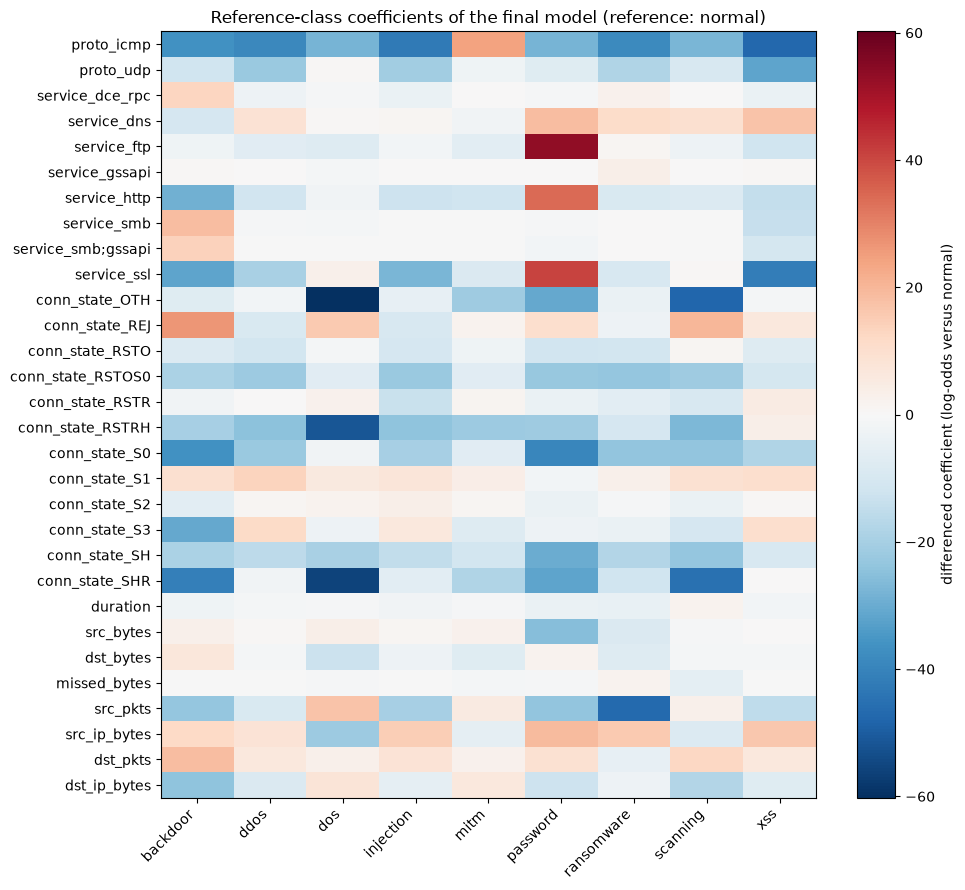

In [12]:
# TODO: the required coefficient plot
# Remove the reference column: it is all zeros and adds nothing to the figure
plot_table = coef_diff.drop(columns=REFERENCE_NAME)

# Symmetric colour limits, so that 0 is always the white centre of the colour map
limit = np.abs(plot_table.to_numpy()).max()

fig, ax = plt.subplots(figsize=(10,9))
# Red = positive coefficient, blue = negative, white = close to zero
image = ax.imshow(plot_table.to_numpy(), cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")

# Class names on the x axis, predictor names on the y axis
ax.set_xticks(range(len(plot_table.columns)))
ax.set_xticklabels(plot_table.columns, rotation=45, ha="right")
ax.set_yticks(range(len(plot_table.index)))
ax.set_yticklabels(plot_table.index)

fig.colorbar(image, ax=ax, label="differenced coefficient (log-odds versus " + REFERENCE_NAME + ")")
ax.set_title("Reference-class coefficients of the final model (reference: " + REFERENCE_NAME + ")")
fig.tight_layout()
plt.show()

**Interpretation of the figure.** 

Each cell is a differenced coefficient $w_c$: the change in log-odds of the class in the column versus `normal` when the predictor in the row goes up by one unit (one dummy switched on, or one standard deviation of `log1p` for a numeric column). The colour scale goes to ±60.2, set by `conn_state_OTH` for `dos`.

1. **The categorical dummies carry the strongest effects.** `proto_icmp` is strongly negative for every attack except `mitm` (+24.1), so ICMP traffic points to either `normal` or `mitm`. `service_ftp`, `service_ssl` and `service_http` are strongly positive only for `password` (+53.4, +40.6, +34.3), and `service_smb`, `service_smb;gssapi` and `service_dce_rpc` mainly for `backdoor` (+18.4, +14.0, +12.7). `conn_state_REJ` is positive for `backdoor` (+26.4), `scanning` (+19.9) and `dos` (+15.9), which matches rejected connection attempts. Most other `conn_state` rows (`OTH`, `RSTOS0`, `RSTRH`, `S0`, `SH`, `SHR`) are blue for almost every class, so, compared with `SF`, these states push the prediction towards `normal`.
2. **The numeric packet and byte counts come in pairs with opposite signs.** For `backdoor`, `src_pkts` is −23.1 against `src_ip_bytes` +12.2, and `dst_pkts` +18.7 against `dst_ip_bytes` −24.1. These pairs are strongly correlated (IP bytes grow with the number of packets), so the model offsets one with the other. Their signs should not be read one by one; only their combination is meaningful.
3. **Many coefficients are above 20 in absolute value**, which means odds ratios above $e^{20} \approx 5 \times 10^8$. This is the expected sign of an unpenalised model on almost separable classes. The figure shows which predictors and directions matter, but not reliable effect sizes.

# P3.5 — Challenge A against Practice 2

In [14]:
# TODO: the paired per-fold differences
# Macro F1 of the Practice 2 model on the same five canonical folds
P2_MACRO_F1 = [0.9436, 0.9473, 0.9490, 0.9428, 0.9451]

# Check: the mean must match the value stored in comparativa.csv
assert round(np.mean(P2_MACRO_F1), 4) == 0.9456

# One row per fold: both models side by side
paired = pd.DataFrame({
    "practice_2": P2_MACRO_F1,
    "logreg": lr_macro.to_numpy(),
}, index=lr_macro.index)

# Paired difference: positive means logistic regression did better in that fold
paired["difference"] = paired["logreg"] - paired["practice_2"]
display(paired.round(4))

# Descriptive summary of the five differences
print("mean difference:", round(paired["difference"].mean(), 4))
print("smallest difference:", round(paired["difference"].min(), 4))
print("largest difference:", round(paired["difference"].max(), 4))
print("folds where logistic regression is better:", (paired["difference"] > 0).sum(), "of 5")

# Macro F1 of the Dummy baseline in Practice 2
DUMMY_MACRO_F1 = 0.0242
# Gap between the Dummy and a perfect score of 1
gap = 1 - DUMMY_MACRO_F1
# Share of that gap closed by each model, in percent
print("KNN closes:", round((np.mean(P2_MACRO_F1) - DUMMY_MACRO_F1)/gap*100, 1), "% of the gap")
print("logistic regression closes:", round((lr_macro.mean() - DUMMY_MACRO_F1) / gap*100, 1), "% of the gap")

,practice_2,logreg,difference
fold,,,
0,0.9436,0.8407,-0.1029
1,0.9473,0.8332,-0.1141
2,0.9490,0.8453,-0.1037
3,0.9428,0.8353,-0.1075
4,0.9451,0.8361,-0.1090


mean difference: -0.1074
smallest difference: -0.1141
largest difference: -0.1029
folds where logistic regression is better: 0 of 5
KNN closes: 94.4 % of the gap
logistic regression closes: 83.4 % of the gap


### The six fixed comparison questions

1. **Size and consistency of the change.** Using the five paired differences (descriptive only). The logistic regression is worse than Practice 2's KNN in **all five folds**: the paired differences in macro F1 go from −0.1141 to −0.1029, with a mean of **−0.1074**. The five differences lie within 0.0112 of each other. That is about ten times smaller than their size, and similar to the fold-to-fold range of the logistic regression itself (0.0121). The drop is therefore large and consistent. This is a descriptive comparison of five paired values, not a statistical test. The logistic regression is also about twice as variable across folds as KNN (macro F1 range 0.0121 against 0.0062, both from the printed per-fold scores).
2. **Route and representation.** Pipeline comparison or isolated family comparison, and what the evidence licenses. Both models use the primary route, the same 11 frozen predictors, the same five canonical folds and almost the same preprocessing, fitted inside each fold (one-hot on the nominal predictors, `log1p` + `StandardScaler` on the numeric ones). The only change in the representation is that the logistic regression drops one reference level per nominal predictor. Strictly this is a pipeline comparison, but a very close one to an isolated family comparison. One asymmetry remains: KNN's `k` was chosen on the same folds it is scored on, so its 0.9456 is slightly optimistic. That optimism is far too small to explain a gap of 0.107. The evidence supports the claim that this unpenalised linear model is clearly worse than this KNN on these folds and this representation, not a general claim about the two families.
3. **What can the new family express** that the previous one could not? Logistic regression gives an explicit probability model and one global coefficient per predictor and class, so each effect can be read as an odds ratio versus `normal`, and the probabilities can be checked by hand (P3.2). KNN only votes among nearby points and has no such summary. In return, logistic regression can only draw boundaries that are linear in the transformed predictors, while KNN can follow non-linear ones. The confusion matrix shows where this matters: `xss` versus `ddos` and `injection`, and `dos` versus `normal` and `scanning`, are classes that overlap and need boundaries that a linear model cannot draw in this representation.
4. **What did it cost** in fitting time, tuning effort and interpretability? *Fitting time:* about 8.0 s per fold, against about 0.035 s for KNN, which only stores the data; at prediction time the order is reversed, because KNN computes one distance per training row. *Tuning effort:* none, against 9 values of `k` for KNN. *Interpretability:* higher in principle, but limited in practice: without a penalty the coefficients reach ±60, correlated pairs such as `src_pkts` and `src_ip_bytes` take opposite signs, and the number of columns changes in fold 3 because of the single `gssapi` row.
5. **Did the ordering of the two challenges' difficulty change**, and why? The two challenges use different metrics, so we compare each model with its own Dummy using the same rule in both: the share of the gap between the Dummy and a perfect score that the model closes (for MAE a perfect score is 0, so this is the relative reduction in MAE). In cyber, KNN closes 94 % of the gap from the Dummy macro F1 (0.0242) to 1, and logistic regression 83 % (macro F1 0.8381 against 0.9456, worse in all five folds). In storage, KNN cuts the Dummy's MAE(z) of 0.677 by 73 % (0.180), and LinearRegression by 71 % ({MAE de R3}). The ordering did not change: storage remains the harder challenge with both families. But the linear model lost much more in cyber (about 11 percentage points against about 3). Our untested explanation: some cyber classes overlap in ways that a linear boundary cannot separate, as the `xss`–`ddos` and `dos`–`normal` confusions show, while z is close to additive in the predictors.
6. **Would you ship the new model?** If not, what would change your mind? No, not as the main detector. It loses about 0.107 macro F1 in every fold, and it misses more than half of the `mitm` connections (recall 0.458), most of them as `normal`. It is useful as an interpretable reference, to explain which services and connection states are associated with each attack. What would change our mind: a penalised logistic regression, with `C` tuned on the same folds and with interaction terms (for example `service` × `conn_state`), that closes the gap to KNN to within the fold-to-fold range (about 0.01) while keeping coefficients of a readable size.